# Historical NH₃ search example

Six real MACE runs from the earlier four-adsorbate implementation; exact k=2,3,5 and two seeds each. These data illustrate historical behavior, **not the revised release protocol**. Contact screening and clean-reference sampling have since changed. Mean-window hits are distinct from conservative interval hits or reaction activity.

All plotting settings below are editable. The shaded band is sample standard deviation across **two seeds**, not a confidence interval or evidence that one k is superior. PNG is the only figure export format.

In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt

K_VALUES = [2, 3, 5]
SEEDS = [123, 124]
COLORS = {2: 'red', 3: 'green', 5: 'blue'}
BAND_ALPHA = 0.15
SAVE_PNG = True
DPI = 180

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'pyproject.toml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from within the extracted repository')
DATA_DIR = ROOT/'examples/historical_nh3'
OUTPUT_DIR = DATA_DIR
payload = json.loads((DATA_DIR/'historical_nh3.json').read_text())
runs = [r for r in payload['runs'] if r['config']['k'] in K_VALUES and r['config']['seed'] in SEEDS]
if not runs:
    raise ValueError('No runs match the chosen settings')
print('Source archive SHA-256:', payload['source_sha256'])
print('Protocol:', payload['protocol'])

Source archive SHA-256: 5188a4449e2c0819640001871beb6f82449e43d826b5908ab4569b4a7b33d1a2
Protocol: Earlier toy GP implementation; not the release protocol


In [2]:
summary = [r for r in payload['summary'] if r['k'] in K_VALUES and r['seed'] in SEEDS]
print('Run                 unique   eligible finalists   four-window hits   app. hours')
for r in summary:
    print(f"{r['run']:<20} {r['unique_search_genomes']:>5}       {r['eligible_finalists']:>2}/{r['validation_finalists']:<2}"
          f"                  {r['all_four_mean_hits']:>2}           {r['application_hours']:>6.2f}")
print('Fitness/hits use original recorded validity flags. Application time is not billed GPU time.')

Run                 unique   eligible finalists   four-window hits   app. hours
gp_k2_seed123          240        8/8                    5             9.65
gp_k2_seed124          240        6/8                    1            11.73
gp_k3_seed123          240        8/8                    3            10.99
gp_k3_seed124          240        7/8                    4            10.87
gp_k5_seed123          240        8/8                    5            10.48
gp_k5_seed124          240        8/8                    3            11.00
Fitness/hits use original recorded validity flags. Application time is not billed GPU time.


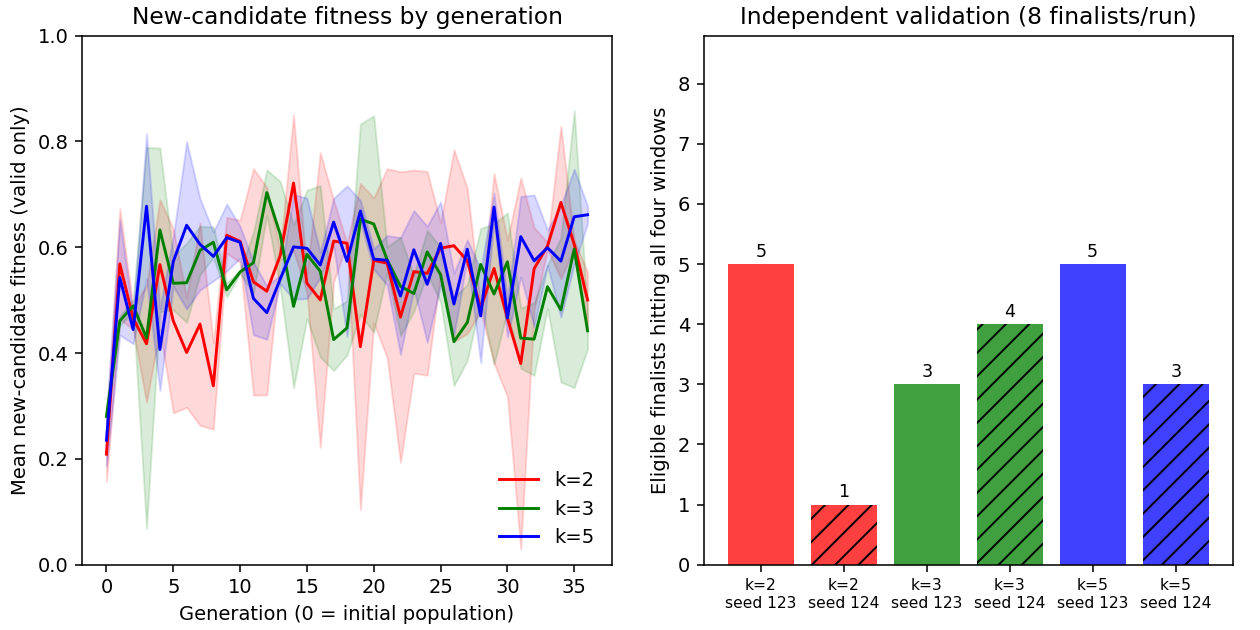

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)
for k in K_VALUES:
    selected = [r for r in runs if r['config']['k'] == k]
    if not selected:
        continue
    generations = sorted({v['generation'] for r in selected for v in r['search']})
    profiles = []
    for r in selected:
        profile = []
        for gen in generations:
            scores = [v['score'] for v in r['search'] if v['generation'] == gen and v['valid']]
            profile.append(np.mean(scores) if scores else np.nan)
        profiles.append(profile)
    profiles = np.asarray(profiles)
    # Summarize only seeds with finite means at a given generation.
    means, sds = [], []
    for column in profiles.T:
        valid = column[np.isfinite(column)]
        means.append(np.mean(valid) if len(valid) else np.nan)
        sds.append(np.std(valid, ddof=1) if len(valid) > 1 else 0.)
    means, sds = np.array(means), np.array(sds)
    axes[0].plot(generations, means, color=COLORS[k], label=f'k={k}')
    axes[0].fill_between(generations, np.maximum(0, means-sds), np.minimum(1, means+sds),
                         color=COLORS[k], alpha=BAND_ALPHA)
axes[0].set(xlabel='Generation (0 = initial population)', ylabel='Mean new-candidate fitness (valid only)',
            ylim=(0, 1), title='New-candidate fitness by generation')
axes[0].legend(loc='lower right', frameon=False)

labels, heights, colors = [], [], []
for r in summary:
    labels.append(f"k={r['k']}\nseed {r['seed']}")
    heights.append(r['all_four_mean_hits'])
    colors.append(COLORS[r['k']])
bars = axes[1].bar(range(len(summary)), heights, color=colors, alpha=.75)
for bar, row in zip(bars, summary):
    if row['seed'] == 124:
        bar.set_hatch('//')
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+.12,
                 str(row['all_four_mean_hits']), ha='center', fontsize=9)
axes[1].set(xticks=range(len(summary)), xticklabels=labels, ylabel='Eligible finalists hitting all four windows',
            ylim=(0, 8.8), title='Independent validation (8 finalists/run)')
axes[1].tick_params(axis='x', labelsize=8)
for ax in axes:
    ax.set_box_aspect(1)
if SAVE_PNG:
    fig.savefig(OUTPUT_DIR/'historical_overview.png', dpi=DPI)
plt.show()

The first panel averages valid new-candidate scores within each seed/generation, then averages those seed means. It conditions on original validity; changes in validity rates can also affect this curve. The second panel counts independently validated, originally eligible candidates whose **means** lie in all four inclusive windows. Neither panel applies the revised release contact screen retroactively.

`run_summary.csv` contains runtimes and counters for spreadsheet use. Each run evaluated 240 search genomes plus 8 validation finalists; surrogate proposal counters are much larger and are not physical MACE evaluations. Two seeds per k do not support a definitive k ranking.